# Part 2 — Exploratory Data Analysis (EDA)

**Project:** Social Media and Stress Patterns
**Data:** `data/processed/social_media_stress_augmented.csv` (1,500 rows: 500 real + 1,000 synthetic) — the same dataset the models use.

This notebook contains the **actual EDA code**, section by section (the same code as `scripts/eda.py`).
Every section prints its findings in plain English and saves its charts to `reports/figures/` (17 charts).

Sections:
1. Overview (shape, types, summary stats)
2. Missing values (counts + row-level report; heatmap only if gaps exist)
3. Univariate — distributions of the 7 numeric columns (histogram + boxplot + skewness)
4. Univariate — categorical counts (gender, platform, screen-time group)
5. Bivariate — scatter plots and group boxplots with correlation values
6. Correlation heatmap + top-5 strongest relationships
7. Outlier scan (IQR rule, report-only)

In [1]:
from pathlib import Path

import matplotlib

matplotlib.use("Agg")  # save charts to files instead of opening windows

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ---------------------------------------------------------------
# File locations
# ---------------------------------------------------------------
PROJECT = Path.cwd().resolve()
if not (PROJECT / "data" / "processed" / "social_media_stress_augmented.csv").exists():
    PROJECT = PROJECT.parent  # running from notebooks/ instead of the root
AUG_FILE = PROJECT / "data" / "processed" / "social_media_stress_augmented.csv"
FIG_DIR = PROJECT / "reports" / "figures"

sns.set_theme(style="whitegrid")  # nicer chart style

NUMERIC_COLS = [
    "age",
    "daily_screen_time_hours",
    "sleep_quality",
    "stress_level",
    "days_without_social_media",
    "exercise_frequency_per_week",
    "happiness_index",
]

CATEGORICAL_COLS = ["gender", "social_media_platform", "screen_time_group"]


def save_chart(fig, name):
    """Save one chart to reports/figures/ and close it."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / name
    fig.savefig(path, bbox_inches="tight", dpi=120)
    plt.close(fig)
    print(f"    saved -> reports/figures/{name}")


# ================================================================

In [2]:
# Load the augmented dataset (the same 1,500 rows the models use)
df = pd.read_csv(AUG_FILE)
print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns.\n")

Loaded 1500 rows x 11 columns.



## Section 1 - Overview

In [3]:
# SECTION 1 - OVERVIEW
# ================================================================
def overview(df):
    print("=" * 60)
    print("SECTION 1 - OVERVIEW")
    print("=" * 60)
    print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
    print("\nColumn types:")
    print(df.dtypes.to_string())
    print("\nNumeric summary:")
    print(df.describe().round(2).to_string())
    return df


# ================================================================

# Run this section now
df = overview(df)


SECTION 1 - OVERVIEW
Rows: 1500 | Columns: 11

Column types:
user_id                            str
age                              int64
gender                             str
daily_screen_time_hours        float64
sleep_quality                    int64
stress_level                     int64
days_without_social_media        int64
exercise_frequency_per_week      int64
social_media_platform              str
happiness_index                  int64
screen_time_group                  str

Numeric summary:
           age  daily_screen_time_hours  sleep_quality  stress_level  days_without_social_media  exercise_frequency_per_week  happiness_index
count  1500.00                  1500.00        1500.00       1500.00                    1500.00                      1500.00          1500.00
mean     33.41                     5.48           6.32          6.62                       3.18                         2.43             8.38
std      10.00                     1.73           1.63          1.

## Section 2 - Missing Values Heatmap

In [4]:
# SECTION 2 - MISSING VALUES HEATMAP
# ================================================================
def missing_values_heatmap(df):
    """
    Count empty cells and report WHICH rows have them.
    The heatmap is only drawn when gaps actually exist - on a fully
    clean dataset an all-white heatmap carries no information, so we
    print the check result as text instead.
    """
    print("\n" + "=" * 60)
    print("SECTION 2 - MISSING VALUES")
    print("=" * 60)
    total_missing = df.isna().sum().sum()
    print(f"Total missing values in the dataset: {total_missing}")

    # Which exact rows have gaps? Check every cell, one by one.
    found_any = False
    for index, row in df.iterrows():
        for col in df.columns:
            if pd.isna(row[col]):          # is this cell empty?
                found_any = True
                if "user_id" in df.columns:
                    label = row["user_id"]
                else:
                    label = index
                print(f"  {label}: missing in '{col}'")
    if not found_any:
        print("No rows have missing values - every cell is filled.")

    if total_missing > 0:
        fig, ax = plt.subplots(figsize=(10, 3))
        sns.heatmap(df.isna(), cbar=False, yticklabels=False, ax=ax)
        ax.set_title("Missing values heatmap (white = present, coloured = missing)")
        save_chart(fig, "eda_missing_values.png")
    else:
        print("(heatmap skipped - nothing to show on a clean dataset)")
    return df


# ================================================================

# Run this section now
df = missing_values_heatmap(df)



SECTION 2 - MISSING VALUES
Total missing values in the dataset: 0
No rows have missing values - every cell is filled.
(heatmap skipped - nothing to show on a clean dataset)


## Section 3 - Univariate Analysis (One Variable At A Time)

In [5]:
# SECTION 3 - UNIVARIATE ANALYSIS (one variable at a time)
# ================================================================
def univariate_numeric(df):
    """
    For every numeric column: a histogram (shape of the data) next
    to a boxplot (centre, spread and outliers).
    """
    print("\n" + "=" * 60)
    print("SECTION 3 - UNIVARIATE (numeric columns)")
    print("=" * 60)
    for col in NUMERIC_COLS:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
        sns.histplot(df[col], kde=True, ax=ax1)
        ax1.set_title(f"{col} - distribution")
        sns.boxplot(x=df[col], ax=ax2)
        ax2.set_title(f"{col} - boxplot")
        save_chart(fig, f"eda_{col}.png")

        # print the key numbers in plain English
        mean = df[col].mean()
        median = df[col].median()
        skew = df[col].skew()
        print(f"  {col}: mean {mean:.2f}, median {median:.2f}, skewness {skew:+.2f}")
        if skew > 1:
            print(f"      -> strongly right-skewed (long tail of high values)")
        elif skew < -1:
            print(f"      -> strongly left-skewed (long tail of low values)")
        else:
            print(f"      -> roughly symmetric or mildly skewed")
    return df


def univariate_categorical(df):
    """Count each category and draw a bar chart."""
    print("\n" + "=" * 60)
    print("SECTION 3b - UNIVARIATE (categorical columns)")
    print("=" * 60)
    for col in CATEGORICAL_COLS:
        counts = df[col].value_counts()
        print(f"\n  {col} counts:")
        for label, n in counts.items():
            print(f"    {label}: {n} ({n / len(df) * 100:.1f}%)")
        fig, ax = plt.subplots(figsize=(8, 4))
        sns.countplot(data=df, x=col, order=counts.index, ax=ax)
        ax.set_title(f"{col} - counts")
        plt.xticks(rotation=20)
        save_chart(fig, f"eda_{col}_counts.png")
    return df


# ================================================================

# Run this section now
df = univariate_numeric(df)



SECTION 3 - UNIVARIATE (numeric columns)
    saved -> reports/figures/eda_age.png
  age: mean 33.41, median 34.00, skewness -0.17
      -> roughly symmetric or mildly skewed
    saved -> reports/figures/eda_daily_screen_time_hours.png
  daily_screen_time_hours: mean 5.48, median 5.55, skewness +0.04
      -> roughly symmetric or mildly skewed
    saved -> reports/figures/eda_sleep_quality.png
  sleep_quality: mean 6.32, median 6.00, skewness -0.06
      -> roughly symmetric or mildly skewed


    saved -> reports/figures/eda_stress_level.png
  stress_level: mean 6.62, median 7.00, skewness -0.12
      -> roughly symmetric or mildly skewed
    saved -> reports/figures/eda_days_without_social_media.png
  days_without_social_media: mean 3.18, median 3.00, skewness +0.04
      -> roughly symmetric or mildly skewed
    saved -> reports/figures/eda_exercise_frequency_per_week.png
  exercise_frequency_per_week: mean 2.43, median 2.00, skewness +0.25
      -> roughly symmetric or mildly skewed
    saved -> reports/figures/eda_happiness_index.png
  happiness_index: mean 8.38, median 9.00, skewness -0.74
      -> roughly symmetric or mildly skewed


## Section 4 - Bivariate Analysis (Two Variables Together)

In [6]:
# SECTION 4 - BIVARIATE ANALYSIS (two variables together)
# ================================================================
def bivariate(df):
    """
    Scatter plots for two numeric variables, boxplots to compare a
    numeric variable across groups.
    """
    print("\n" + "=" * 60)
    print("SECTION 4 - BIVARIATE (relationships)")
    print("=" * 60)

    # Scatter plots
    scatter_pairs = [
        ("daily_screen_time_hours", "stress_level", "social_media_platform",
         "Screen time vs stress (coloured by platform)"),
        ("daily_screen_time_hours", "sleep_quality", None,
         "Screen time vs sleep quality"),
        ("exercise_frequency_per_week", "happiness_index", None,
         "Exercise vs happiness"),
    ]
    for x_col, y_col, hue, title in scatter_pairs:
        fig, ax = plt.subplots(figsize=(8, 5))
        sns.scatterplot(data=df, x=x_col, y=y_col, hue=hue, alpha=0.6, ax=ax)
        ax.set_title(title)
        if hue:
            ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
        save_chart(fig, f"eda_{x_col}_vs_{y_col}.png")
        corr = df[x_col].corr(df[y_col])
        print(f"  {x_col} vs {y_col}: correlation = {corr:+.2f}")

    # Boxplots across groups
    group_pairs = [
        ("screen_time_group", "stress_level", "Stress by screen-time group"),
        ("social_media_platform", "sleep_quality", "Sleep quality by platform"),
        ("gender", "stress_level", "Stress by gender"),
    ]
    for group_col, value_col, title in group_pairs:
        fig, ax = plt.subplots(figsize=(8, 5))
        sns.boxplot(data=df, x=group_col, y=value_col, ax=ax)
        ax.set_title(title)
        plt.xticks(rotation=20)
        save_chart(fig, f"eda_{value_col}_by_{group_col}.png")
        # print group means
        print(f"\n  Mean {value_col} by {group_col}:")
        for label, mean in df.groupby(group_col)[value_col].mean().round(2).items():
            print(f"    {label}: {mean}")
    return df


# ================================================================

# Run this section now
df = bivariate(df)



SECTION 4 - BIVARIATE (relationships)


    saved -> reports/figures/eda_daily_screen_time_hours_vs_stress_level.png
  daily_screen_time_hours vs stress_level: correlation = +0.72
    saved -> reports/figures/eda_daily_screen_time_hours_vs_sleep_quality.png
  daily_screen_time_hours vs sleep_quality: correlation = -0.72
    saved -> reports/figures/eda_exercise_frequency_per_week_vs_happiness_index.png
  exercise_frequency_per_week vs happiness_index: correlation = +0.01
    saved -> reports/figures/eda_stress_level_by_screen_time_group.png

  Mean stress_level by screen_time_group:
    0-3 hrs: 4.34
    3-6 hrs: 6.04
    6-9 hrs: 7.61
    9-12 hrs: 9.07
    saved -> reports/figures/eda_sleep_quality_by_social_media_platform.png

  Mean sleep_quality by social_media_platform:
    Facebook: 6.04
    Instagram: 5.94
    LinkedIn: 6.53
    TikTok: 6.52
    X (Twitter): 6.52
    YouTube: 6.3
    saved -> reports/figures/eda_stress_level_by_gender.png

  Mean stress_level by gender:
    Female: 6.64
    Male: 6.62
    Other: 6.48

## Section 5 - Correlation

In [7]:
# SECTION 5 - CORRELATION
# ================================================================
def correlations(df):
    """
    Correlation measures how two numbers move together:
      +1 = move together, -1 = move opposite, 0 = no link.
    """
    print("\n" + "=" * 60)
    print("SECTION 5 - CORRELATION")
    print("=" * 60)
    corr = df[NUMERIC_COLS].corr()

    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
                center=0, square=True, ax=ax)
    ax.set_title("Correlation heatmap (numeric columns)")
    save_chart(fig, "eda_correlation_heatmap.png")

    # Find the strongest links (ignore a variable with itself)
    print("\n  Strongest relationships:")
    pairs = []
    for i in range(len(NUMERIC_COLS)):
        for j in range(i + 1, len(NUMERIC_COLS)):
            col_a, col_b = NUMERIC_COLS[i], NUMERIC_COLS[j]
            pairs.append((abs(corr.loc[col_a, col_b]), col_a, col_b, corr.loc[col_a, col_b]))
    for strength, col_a, col_b, value in sorted(pairs, reverse=True)[:5]:
        direction = "positive" if value > 0 else "negative"
        print(f"    {col_a} <-> {col_b}: {value:+.2f} ({direction})")
    return df


# ================================================================

# Run this section now
df = correlations(df)



SECTION 5 - CORRELATION


    saved -> reports/figures/eda_correlation_heatmap.png

  Strongest relationships:
    daily_screen_time_hours <-> stress_level: +0.72 (positive)
    daily_screen_time_hours <-> sleep_quality: -0.72 (negative)
    stress_level <-> happiness_index: -0.69 (negative)
    daily_screen_time_hours <-> happiness_index: -0.68 (negative)
    sleep_quality <-> happiness_index: +0.61 (positive)


## Section 6 - Outlier Scan

In [8]:
# SECTION 6 - OUTLIER SCAN
# ================================================================
def outlier_scan(df):
    """
    Same IQR rule as the cleaning script: report values beyond
    1.5 x IQR from the quartiles. We look, we do not delete.
    """
    print("\n" + "=" * 60)
    print("SECTION 6 - OUTLIER SCAN (IQR rule)")
    print("=" * 60)
    for col in NUMERIC_COLS:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        low_fence = q1 - 1.5 * iqr
        high_fence = q3 + 1.5 * iqr
        n_out = ((df[col] < low_fence) | (df[col] > high_fence)).sum()
        print(f"  {col}: {n_out} potential outlier(s) "
              f"(outside {low_fence:.1f} - {high_fence:.1f})")
    return df


# ================================================================
# MAIN
# ================================================================
def main():
    print("STARTING THE EDA")
    df = pd.read_csv(AUG_FILE)
    print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns from the cleaned file.\n")

    df = overview(df)
    df = missing_values_heatmap(df)
    df = univariate_numeric(df)
    df = univariate_categorical(df)
    df = bivariate(df)
    df = correlations(df)
    df = outlier_scan(df)

    print("\nEDA FINISHED - all charts are in reports/figures/")

# Run this section now
df = outlier_scan(df)



SECTION 6 - OUTLIER SCAN (IQR rule)
  age: 0 potential outlier(s) (outside -0.5 - 67.5)
  daily_screen_time_hours: 5 potential outlier(s) (outside 0.5 - 10.4)
  sleep_quality: 2 potential outlier(s) (outside 2.0 - 10.0)
  stress_level: 3 potential outlier(s) (outside 3.0 - 11.0)
  days_without_social_media: 0 potential outlier(s) (outside -2.5 - 9.5)
  exercise_frequency_per_week: 6 potential outlier(s) (outside -2.0 - 6.0)
  happiness_index: 0 potential outlier(s) (outside 2.5 - 14.5)


**EDA result — the headline numbers (1,500 rows):**
- Screen time ↔ stress: **+0.72** · screen time ↔ sleep: **−0.72** · stress ↔ happiness: **−0.69**
- Stress rises step by step with usage: **4.3 → 6.0 → 7.6 → 9.1**
- Age and gender barely matter (|r| ≤ 0.06)
- Only 146 users (9.7%) are Low-stress → class imbalance expected in the tree

17 EDA charts:

### eda_age.png


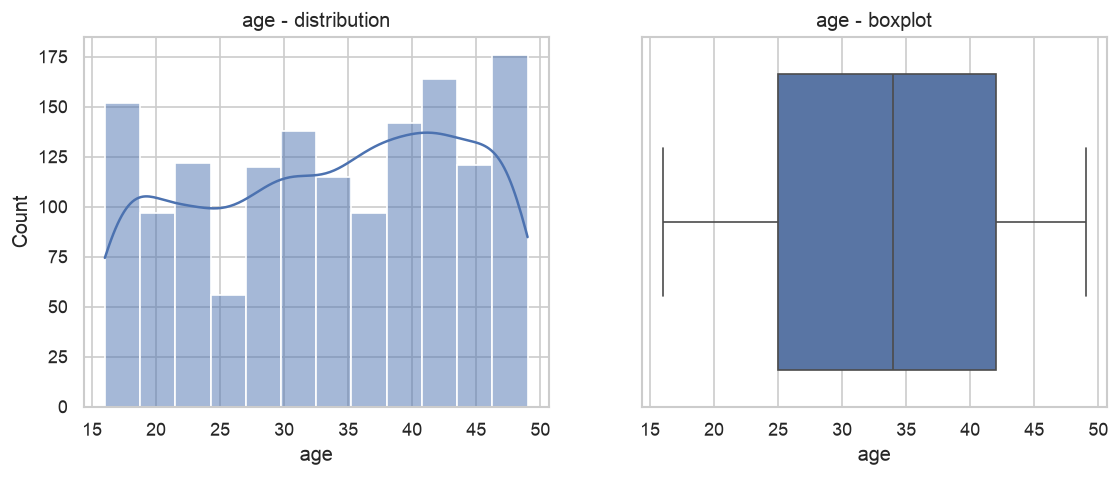


### eda_correlation_heatmap.png


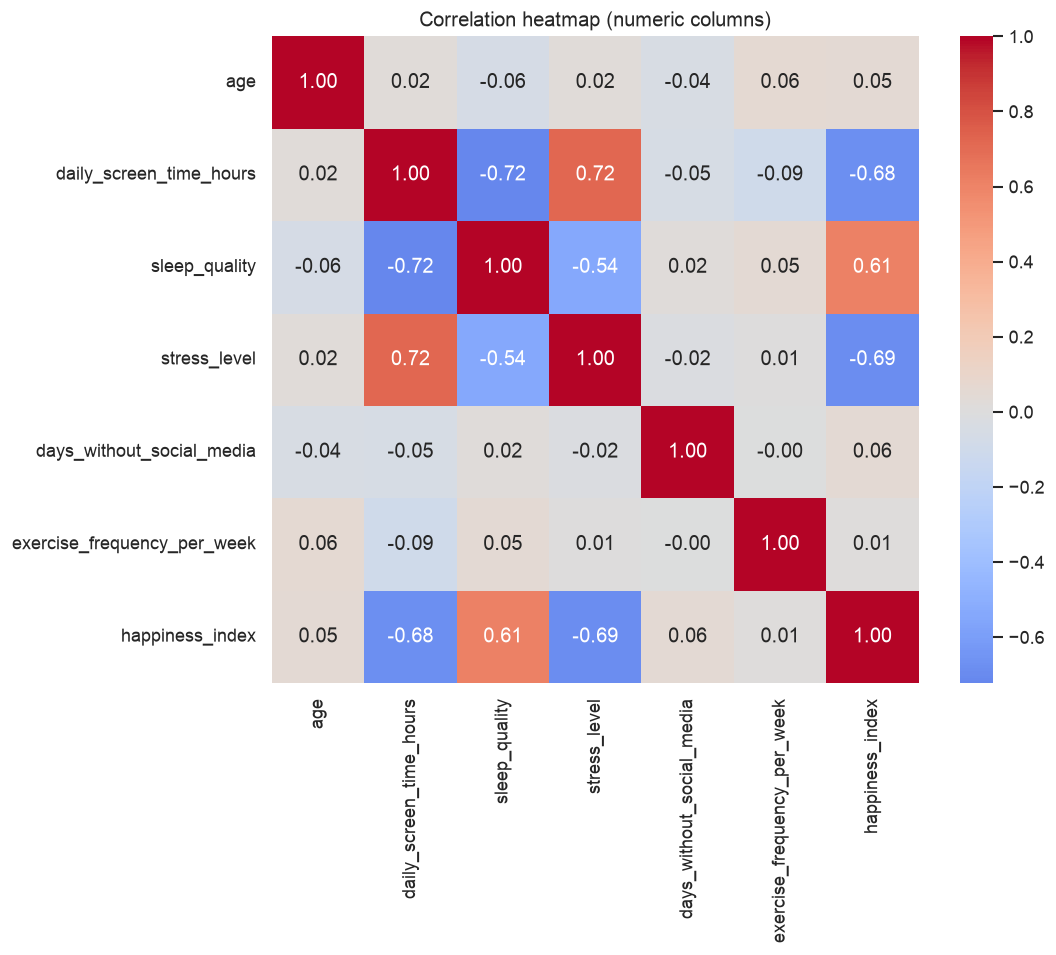


### eda_daily_screen_time_hours.png


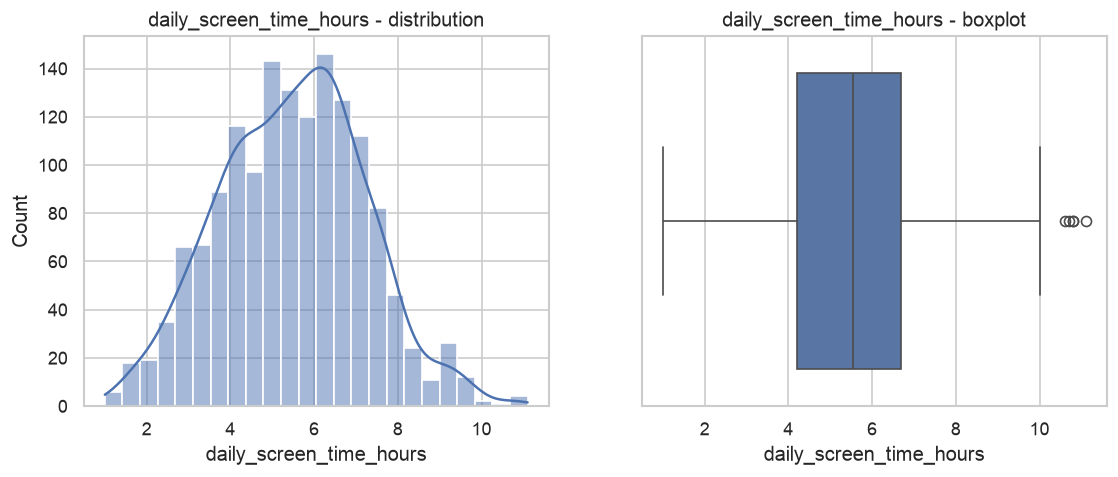


### eda_daily_screen_time_hours_vs_sleep_quality.png


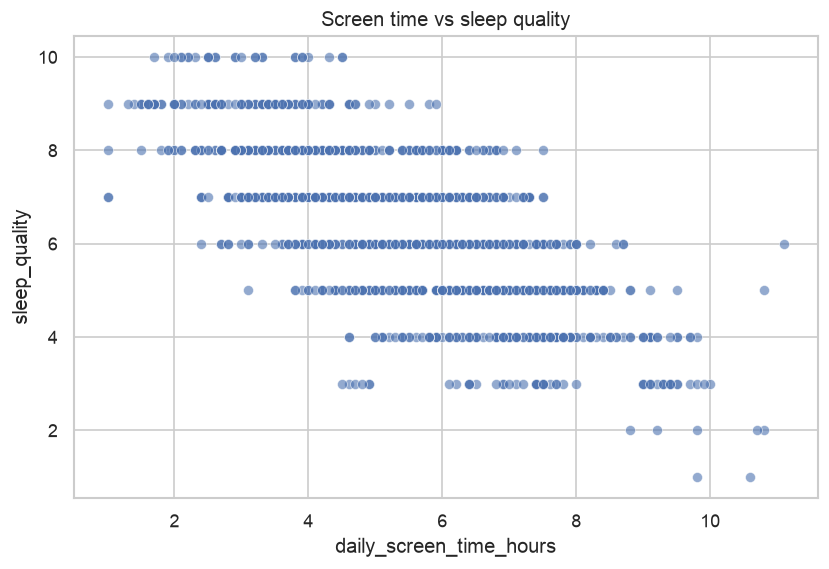


### eda_daily_screen_time_hours_vs_stress_level.png


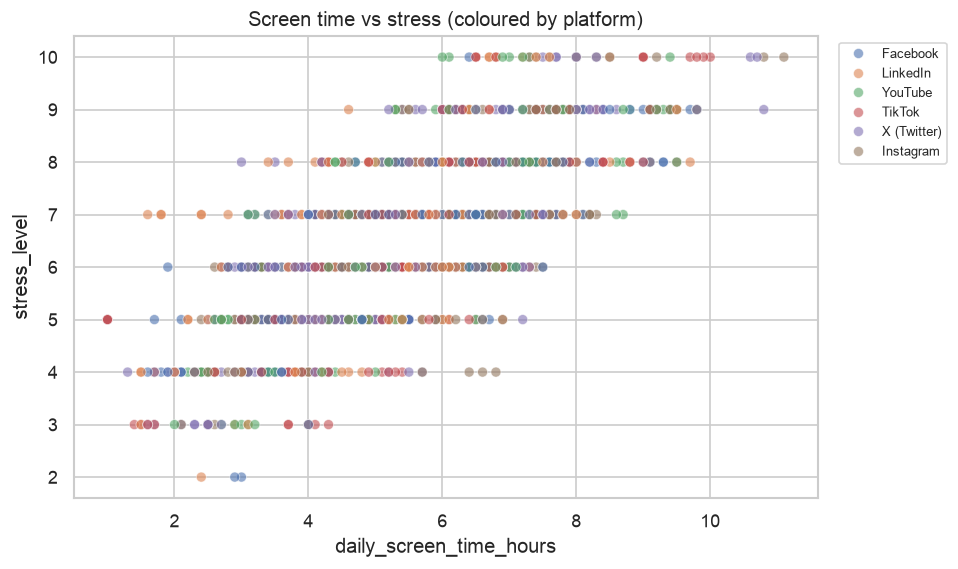


### eda_days_without_social_media.png


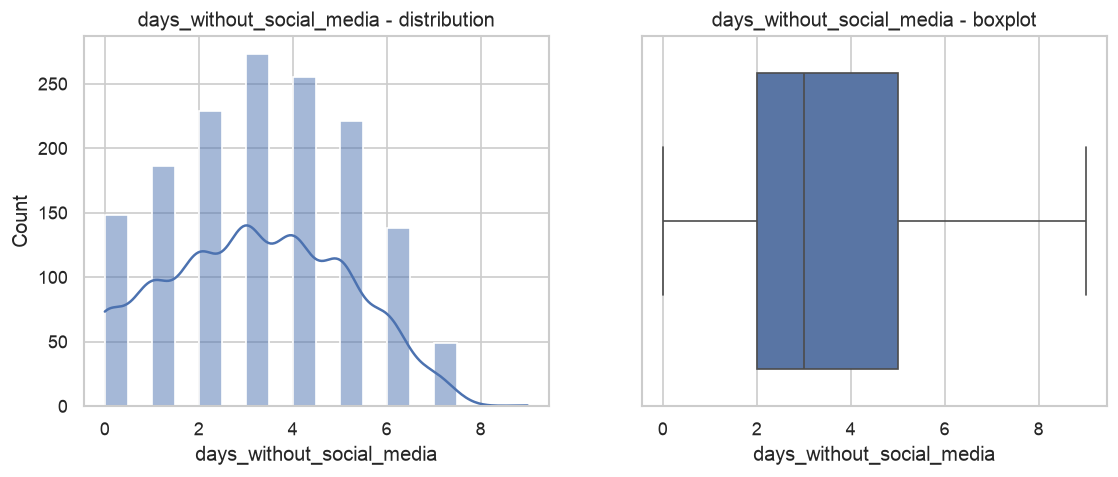


### eda_exercise_frequency_per_week.png


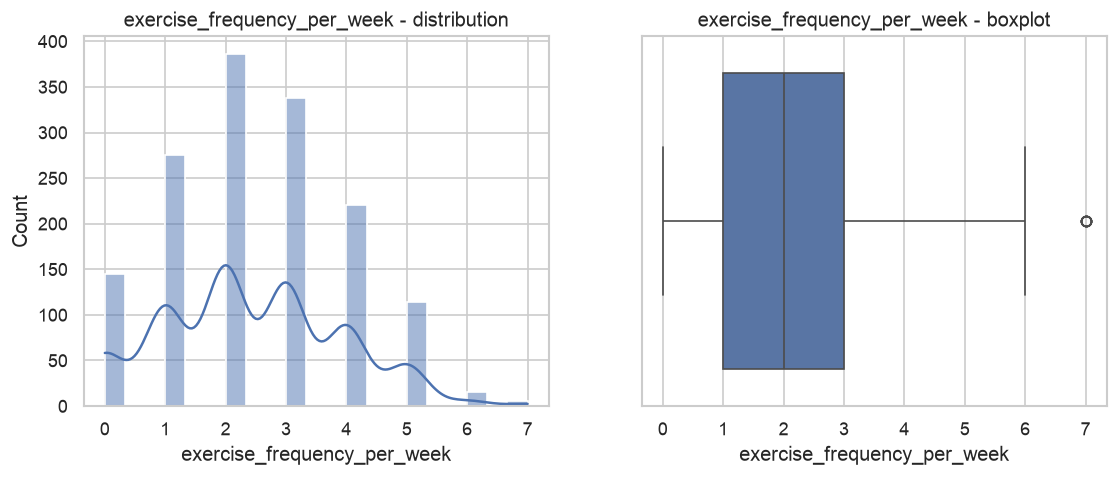


### eda_exercise_frequency_per_week_vs_happiness_index.png


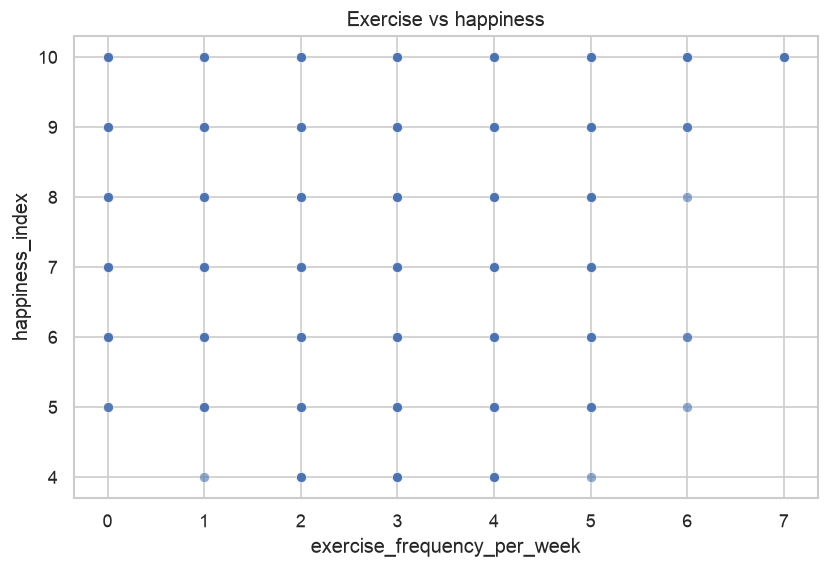


### eda_gender_counts.png


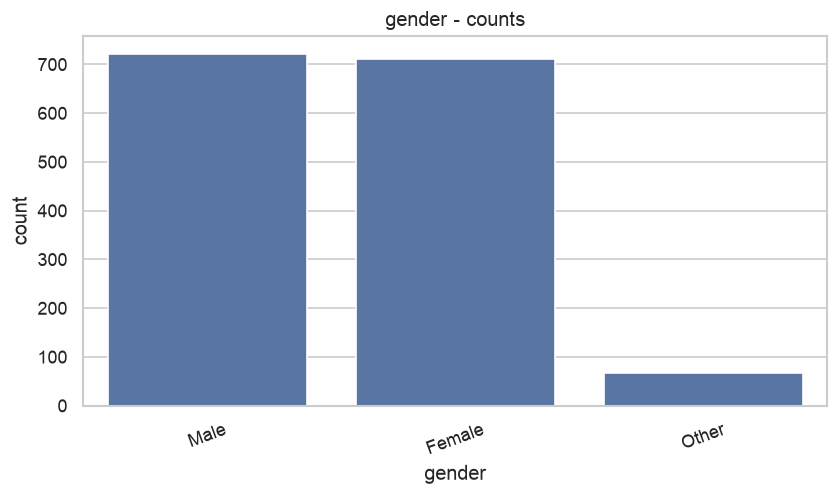


### eda_happiness_index.png


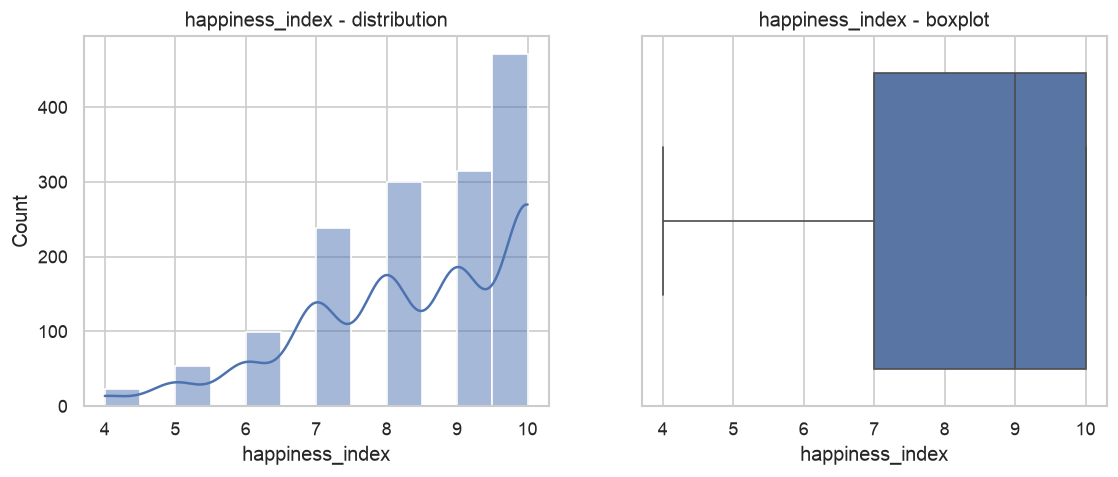


### eda_screen_time_group_counts.png


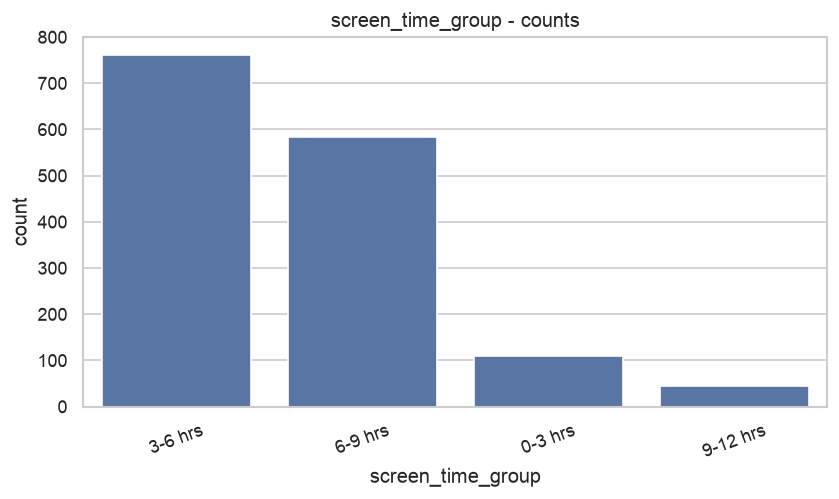


### eda_sleep_quality.png


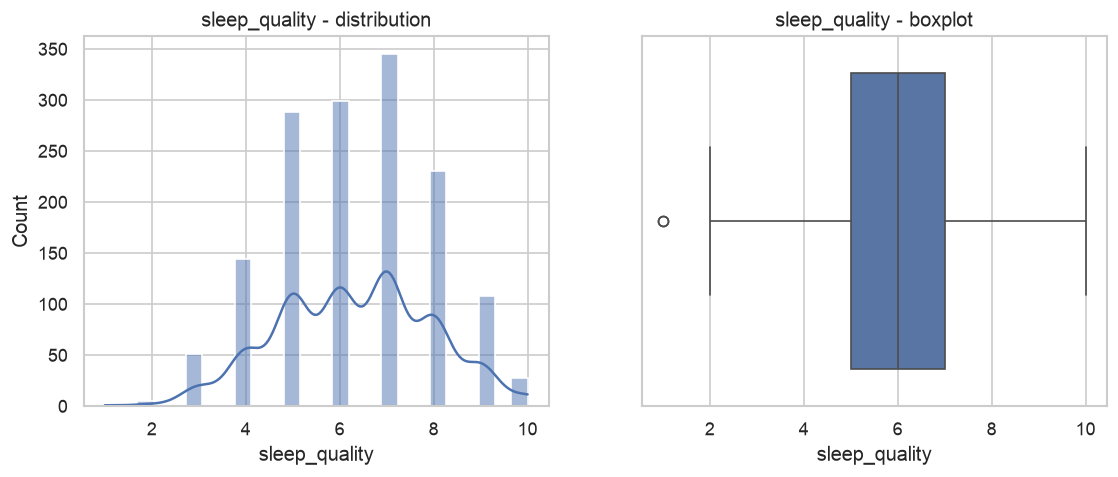


### eda_sleep_quality_by_social_media_platform.png


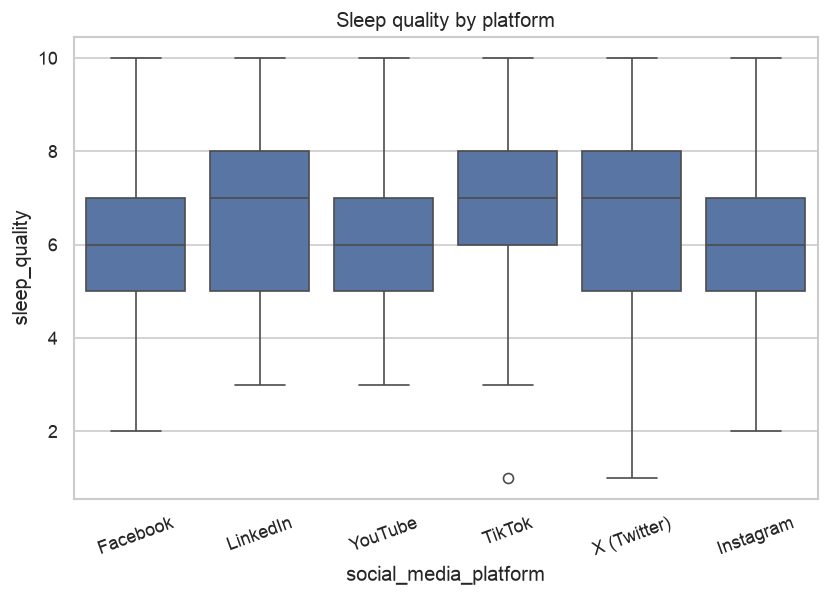


### eda_social_media_platform_counts.png


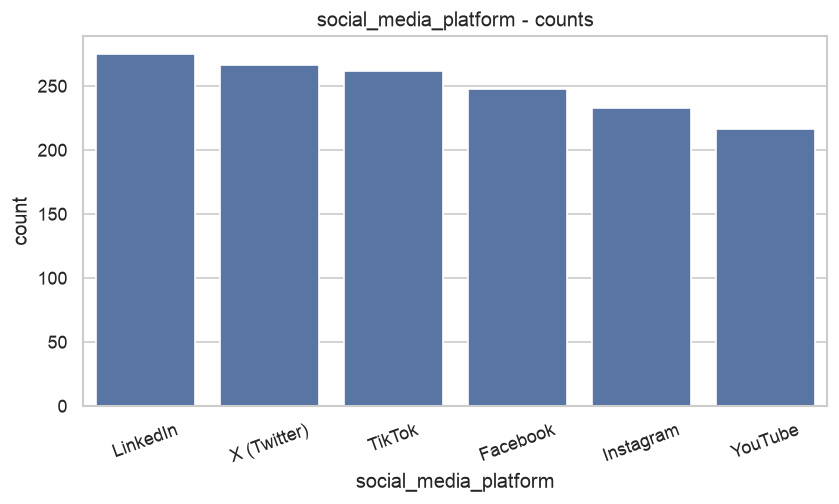


### eda_stress_level.png


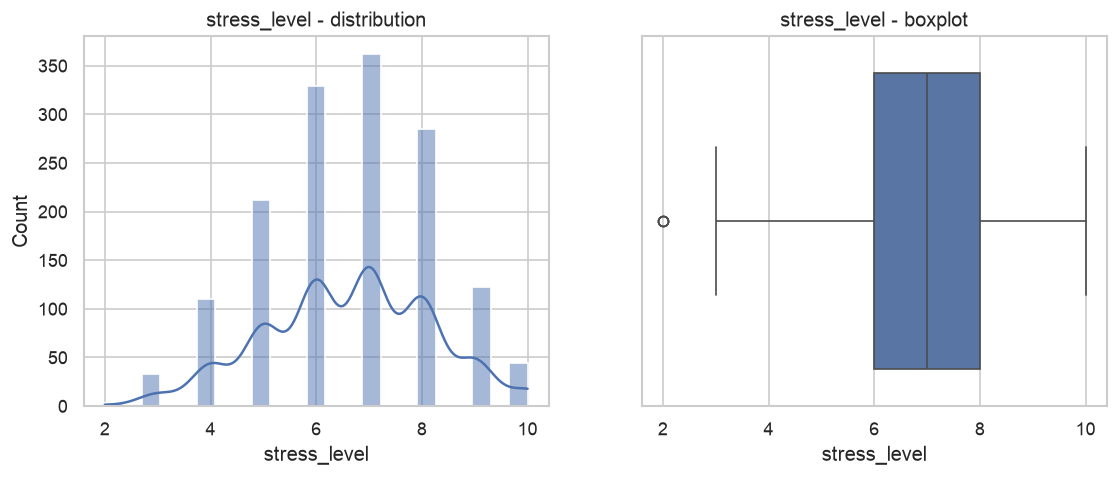


### eda_stress_level_by_gender.png


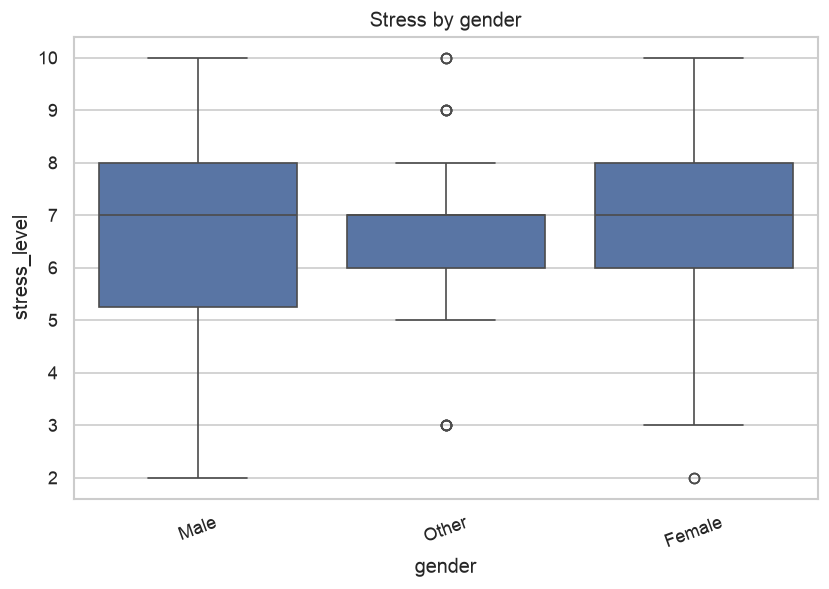


### eda_stress_level_by_screen_time_group.png


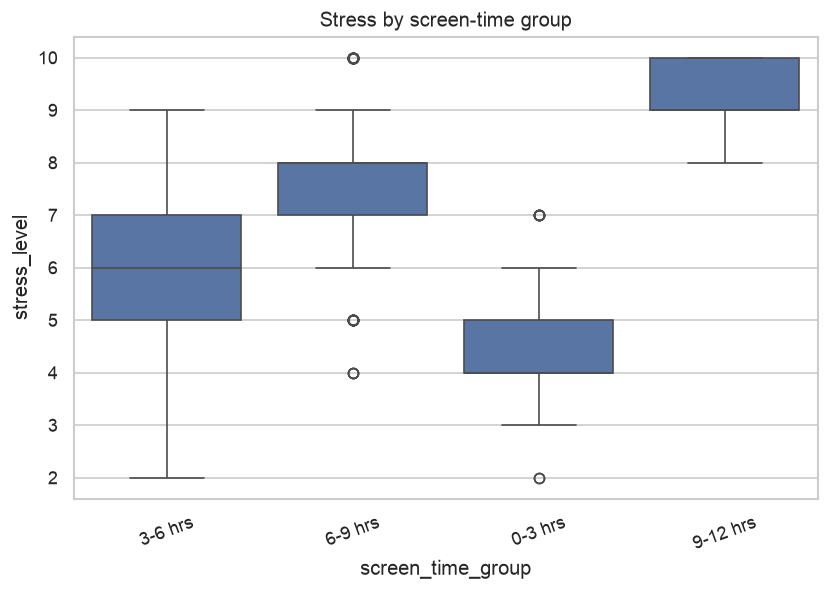

In [9]:
# Show every EDA chart inline so the whole analysis can be reviewed here.
from IPython.display import Image, display

figures = sorted((PROJECT / "reports" / "figures").glob("eda_*.png"))
print(f"{len(figures)} EDA charts:")

for path in figures:
    print("\n###", path.name)
    display(Image(filename=str(path)))